In [1]:

!pip install -q nltk scikit-learn seaborn matplotlib pandas

import nltk
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries imported successfully!")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries imported successfully!


In [2]:

corpus = {

    "symptoms": [
        "What are the symptoms of diabetes?",
        "What are the early signs of diabetes?",
        "Why do diabetic patients feel thirsty?",
        "Can diabetes cause frequent urination?",
        "Why do I feel tired due to diabetes?",
        "Can diabetes cause blurred vision?",
        "What are the symptoms of low blood sugar?",
        "What happens when blood sugar becomes high?"
    ],

    "risk_factors": [
        "What causes diabetes?",
        "Does obesity increase diabetes risk?",
        "Can family history cause diabetes?",
        "Does eating too much sugar cause diabetes?",
        "Can lack of exercise increase diabetes risk?",
        "Does age increase the risk of diabetes?",
        "Can high blood pressure increase diabetes risk?",
        "What are the major risk factors for type 2 diabetes?"
    ],

    "prevention": [
        "How can I prevent diabetes?",
        "How can I reduce my diabetes risk?",
        "What lifestyle changes prevent diabetes?",
        "How can I avoid developing type 2 diabetes?",
        "Does maintaining healthy weight prevent diabetes?",
        "Can regular exercise prevent diabetes?",
        "How important is sleep for diabetes prevention?",
        "What daily habits help prevent diabetes?"
    ],

    "diet": [
        "What foods are good for diabetic patients?",
        "Which fruits can diabetic patients eat?",
        "Should diabetic patients avoid sugar?",
        "What is a healthy diet for diabetes?",
        "Can oats help control blood sugar?",
        "Which vegetables are suitable for diabetics?",
        "Are whole grains good for diabetes?",
        "What foods should diabetic patients limit?"
    ],

    "exercise": [
        "What exercises are good for diabetes?",
        "Can walking reduce blood sugar?",
        "How much exercise should diabetic patients do?",
        "Is cycling good for diabetes?",
        "Can yoga help manage diabetes?",
        "Does physical activity improve insulin sensitivity?",
        "Is swimming beneficial for diabetic patients?",
        "How does exercise control blood glucose?"
    ],

    "monitoring": [
        "How often should I check my blood sugar?",
        "What is a normal blood glucose level?",
        "What is an HbA1c test?",
        "How does a glucometer work?",
        "Why is regular glucose monitoring important?",
        "What does fasting blood sugar mean?",
        "How often should diabetic patients get tested?",
        "What tests help monitor diabetes?"
    ]
}

# Create labelled dataset

queries = []
labels = []

for intent, examples in corpus.items():
    for query in examples:
        queries.append(query)
        labels.append(intent)

df = pd.DataFrame({
    "query": queries,
    "intent": labels
})

print("Total Queries:", len(df))

print("\nIntent Distribution:")
print(df["intent"].value_counts())

print("\nLabelled Dataset:")
display(df)


Total Queries: 48

Intent Distribution:
intent
symptoms        8
risk_factors    8
prevention      8
diet            8
exercise        8
monitoring      8
Name: count, dtype: int64

Labelled Dataset:


,query,intent
0,What are the symptoms of diabetes?,symptoms
1,What are the early signs of diabetes?,symptoms
2,Why do diabetic patients feel thirsty?,symptoms
3,Can diabetes cause frequent urination?,symptoms
4,Why do I feel tired due to diabetes?,symptoms
5,Can diabetes cause blurred vision?,symptoms
6,What are the symptoms of low blood sugar?,symptoms
7,What happens when blood sugar becomes high?,symptoms
8,What causes diabetes?,risk_factors
9,Does obesity increase diabetes risk?,risk_factors


In [3]:

# 1. Hierarchical Taxonomy

taxonomy = {
    "Diabetes Basics": {
        "Types of Diabetes": [
            "Type 1 Diabetes",
            "Type 2 Diabetes"
        ],
        "Symptoms": [
            "Early Symptoms",
            "Warning Signs"
        ]
    },

    "Diabetes Risk Management": {
        "Risk Factors": [
            "Genetic Factors",
            "Lifestyle Factors"
        ],
        "Prevention": [
            "Weight Management",
            "Healthy Lifestyle"
        ]
    },

    "Diabetes Lifestyle": {
        "Nutrition": [
            "Healthy Food Choices",
            "Food Restrictions"
        ],
        "Physical Activity": [
            "Aerobic Exercise",
            "Daily Exercise"
        ]
    },

    "Diabetes Clinical Care": {
        "Blood Glucose Monitoring": [
            "Glucometer Testing",
            "Blood Glucose Levels"
        ],
        "Medical Tests": [
            "HbA1c Test",
            "Regular Health Checkups"
        ]
    }
}

print("HIERARCHICAL TAXONOMY")

for main_category, subcategories in taxonomy.items():

    print("\n" + main_category)

    for category, items in subcategories.items():

        print("  -", category)

        for item in items:
            print("      *", item)


# 2. Domain Concepts

concepts = {
    "Diabetes": "A chronic condition affecting blood glucose regulation",

    "Insulin": "Hormone that helps glucose enter body cells",

    "Glucose": "Main source of energy for the body",

    "Pancreas": "Organ responsible for producing insulin",

    "Blood Sugar": "Amount of glucose present in the blood",

    "HbA1c": "Test that estimates average blood glucose over approximately three months",

    "Obesity": "Excess body fat that can increase type 2 diabetes risk",

    "Exercise": "Physical activity that helps improve insulin sensitivity",

    "Nutrition": "Food choices that influence blood glucose levels",

    "Glucometer": "Device used to measure blood glucose"
}

print("\nDOMAIN CONCEPTS")

for concept, description in concepts.items():
    print(concept, ":", description)


# 3. Relationships

relationships = [
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "helps regulate", "Blood Sugar"),
    ("Glucose", "provides energy to", "Body Cells"),
    ("Diabetes", "affects regulation of", "Blood Sugar"),
    ("Obesity", "increases risk of", "Type 2 Diabetes"),
    ("Exercise", "improves", "Insulin Sensitivity"),
    ("Nutrition", "influences", "Blood Sugar"),
    ("HbA1c", "measures", "Average Blood Glucose"),
    ("Glucometer", "measures", "Blood Sugar"),
    ("Physical Activity", "helps manage", "Diabetes"),
    ("Pancreas", "is involved in", "Glucose Regulation"),
    ("Healthy Diet", "supports management of", "Diabetes")
]

print("\nDOMAIN RELATIONSHIPS")

for relation in relationships:
    print(relation[0], "--", relation[1], "-->", relation[2])

print("\nTotal Concepts:", len(concepts))
print("Total Relationships:", len(relationships))


HIERARCHICAL TAXONOMY

Diabetes Basics
  - Types of Diabetes
      * Type 1 Diabetes
      * Type 2 Diabetes
  - Symptoms
      * Early Symptoms
      * Warning Signs

Diabetes Risk Management
  - Risk Factors
      * Genetic Factors
      * Lifestyle Factors
  - Prevention
      * Weight Management
      * Healthy Lifestyle

Diabetes Lifestyle
  - Nutrition
      * Healthy Food Choices
      * Food Restrictions
  - Physical Activity
      * Aerobic Exercise
      * Daily Exercise

Diabetes Clinical Care
  - Blood Glucose Monitoring
      * Glucometer Testing
      * Blood Glucose Levels
  - Medical Tests
      * HbA1c Test
      * Regular Health Checkups

DOMAIN CONCEPTS
Diabetes : A chronic condition affecting blood glucose regulation
Insulin : Hormone that helps glucose enter body cells
Glucose : Main source of energy for the body
Pancreas : Organ responsible for producing insulin
Blood Sugar : Amount of glucose present in the blood
HbA1c : Test that estimates average blood glucose 

In [4]:

lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words("english"))

# Keep negation words because they can change medical meaning
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("never")

def preprocess_text(text):

    # Lowercase conversion
    text = text.lower()

    # Remove special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


# Apply preprocessing to dataset

df["processed_query"] = df["query"].apply(preprocess_text)

print("PREPROCESSING RESULTS")

display(df[["query", "processed_query"]].head(15))


PREPROCESSING RESULTS


,query,processed_query
0,What are the symptoms of diabetes?,symptom diabetes
1,What are the early signs of diabetes?,early sign diabetes
2,Why do diabetic patients feel thirsty?,diabetic patient feel thirsty
3,Can diabetes cause frequent urination?,diabetes cause frequent urination
4,Why do I feel tired due to diabetes?,feel tired due diabetes
5,Can diabetes cause blurred vision?,diabetes cause blurred vision
6,What are the symptoms of low blood sugar?,symptom low blood sugar
7,What happens when blood sugar becomes high?,happens blood sugar becomes high
8,What causes diabetes?,cause diabetes
9,Does obesity increase diabetes risk?,obesity increase diabetes risk


In [5]:

X = df["processed_query"]
y = df["intent"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# TF-IDF feature extraction
vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Logistic Regression classifier
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

# Predict test data
y_pred = model.predict(X_test_tfidf)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("TF-IDF features:", len(vectorizer.get_feature_names_out()))


Model training completed successfully!
Training samples: 36
Testing samples: 12
TF-IDF features: 72


MODEL EVALUATION
-------------------------
Accuracy : 0.25
Precision: 0.1389
Recall   : 0.25
F1 Score : 0.1667

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        diet       0.00      0.00      0.00         2
    exercise       0.00      0.00      0.00         2
  monitoring       0.50      0.50      0.50         2
  prevention       0.00      0.00      0.00         2
risk_factors       0.33      1.00      0.50         2
    symptoms       0.00      0.00      0.00         2

    accuracy                           0.25        12
   macro avg       0.14      0.25      0.17        12
weighted avg       0.14      0.25      0.17        12



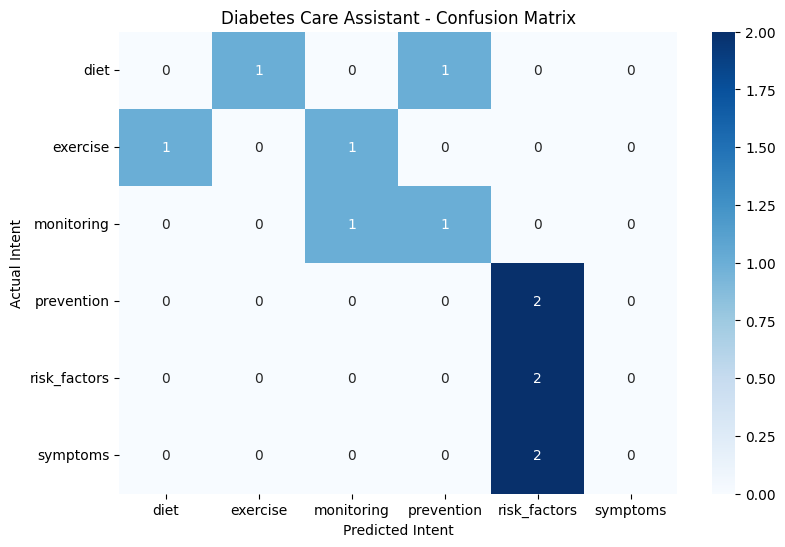

In [6]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print("MODEL EVALUATION")
print("-------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Diabetes Care Assistant - Confusion Matrix")

plt.show()


In [7]:

knowledge_base = {

    "symptoms": """
    Common symptoms of diabetes include frequent urination,
    increased thirst, increased hunger, unexplained weight loss,
    tiredness and blurred vision.

    Some people with type 2 diabetes may have no noticeable symptoms.
    Low blood sugar can cause sweating, shaking, hunger and confusion.
    """,

    "risk_factors": """
    Risk factors for type 2 diabetes include family history,
    obesity, physical inactivity, increasing age and a history
    of prediabetes or gestational diabetes.

    Type 1 diabetes involves autoimmune destruction of insulin-producing
    cells and is not caused simply by lifestyle choices.
    """,

    "prevention": """
    Type 2 diabetes risk can often be reduced through healthy eating,
    regular physical activity, maintaining a healthy weight,
    adequate sleep and regular medical checkups.

    Type 1 diabetes currently cannot be reliably prevented through
    lifestyle changes.
    """,

    "diet": """
    A diabetes-friendly diet includes vegetables, whole grains,
    legumes, fruits in appropriate portions and healthy fats.

    Limit sugary drinks, excess added sugar and highly processed foods.
    Consistent carbohydrate intake and portion control can help
    manage blood glucose levels.
    """,

    "exercise": """
    Regular exercise helps improve insulin sensitivity and blood
    glucose management.

    Walking, cycling, swimming and other aerobic activities are useful.
    Many adults with diabetes are advised to aim for at least
    150 minutes of moderate physical activity per week, if appropriate.

    Blood glucose monitoring and medical advice may be necessary
    before changing exercise routines.
    """,

    "monitoring": """
    Diabetes monitoring may include fasting blood glucose,
    post-meal glucose measurements and HbA1c testing.

    A glucometer measures blood glucose at a particular moment.
    HbA1c estimates average blood glucose over approximately
    the previous three months.

    Testing frequency and personal targets should be decided
    with a healthcare professional.
    """
}

print("DIABETES KNOWLEDGE BASE")

for intent, information in knowledge_base.items():

    print("\nIntent:", intent)
    print(information)


DIABETES KNOWLEDGE BASE

Intent: symptoms

    Common symptoms of diabetes include frequent urination,
    increased thirst, increased hunger, unexplained weight loss,
    tiredness and blurred vision.

    Some people with type 2 diabetes may have no noticeable symptoms.
    Low blood sugar can cause sweating, shaking, hunger and confusion.
    

Intent: risk_factors

    Risk factors for type 2 diabetes include family history,
    obesity, physical inactivity, increasing age and a history
    of prediabetes or gestational diabetes.

    Type 1 diabetes involves autoimmune destruction of insulin-producing
    cells and is not caused simply by lifestyle choices.
    

Intent: prevention

    Type 2 diabetes risk can often be reduced through healthy eating,
    regular physical activity, maintaining a healthy weight,
    adequate sleep and regular medical checkups.

    Type 1 diabetes currently cannot be reliably prevented through
    lifestyle changes.
    

Intent: diet

    A diabet

In [11]:

# Emergency symptoms and warning signs

emergency_keywords = [
    "chest pain",
    "chest pressure",
    "severe chest discomfort",
    "unconscious",
    "seizure",
    "cannot breathe",
    "can't breathe",
    "difficulty breathing",
    "severe confusion",
    "fainting",
    "severe weakness",
    "vomiting with high blood sugar",
    "vomiting",
    "confusion",
    "blood sugar is very high",
    "very low blood sugar",
    "severe hypoglycemia",
    "severe hyperglycemia",
    "low blood sugar and confusion",
    "high blood sugar and vomiting"
]

# Healthcare topics outside the assistant's scope

unsupported_topics = [
    "kidney",
    "asthma",
    "migraine",
    "cancer",
    "skin disease",
    "toothache",
    "dental",
    "pregnancy",
    "fracture",
    "appendicitis"
]

# Diabetes-related vocabulary

diabetes_terms = [
    "diabetes",
    "diabetic",
    "glucose",
    "blood sugar",
    "insulin",
    "hba1c",
    "glucometer",
    "pancreas",
    "sugar level",
    "type 1",
    "type 2",
    "prediabetes",
    "hypoglycemia",
    "hyperglycemia",
    "carbohydrate",
    "carbs",
    "sugary",
    "insulin sensitivity"
]

# Confidence threshold

CONFIDENCE_THRESHOLD = 0.38


def diabetes_assistant(user_query):

    query = user_query.lower()

    # RULE 1: Emergency escalation

    if any(keyword in query for keyword in emergency_keywords):

        return """
        EMERGENCY ALERT

        Your query contains symptoms that may indicate a serious
        medical emergency.

        Seek immediate medical attention or contact emergency
        services. In India, you can call 112.

        Do not wait for an online response or attempt to
        self-diagnose.

        This assistant cannot manage medical emergencies.
        """

    # RULE 2: Unsupported healthcare topics

    if any(topic in query for topic in unsupported_topics):

        return """
        OUT OF SCOPE

        This assistant is specifically designed for diabetes care.

        Your question appears to concern another healthcare topic.

        Please consult an appropriate healthcare professional.
        """

    # NLP preprocessing

    processed_query = preprocess_text(user_query)

    # TF-IDF transformation

    query_vector = vectorizer.transform([processed_query])

    # Predict intent

    probabilities = model.predict_proba(query_vector)[0]

    predicted_index = probabilities.argmax()

    predicted_intent = model.classes_[predicted_index]

    confidence = probabilities[predicted_index]

    # RULE 3: Low-confidence handling

    if confidence < CONFIDENCE_THRESHOLD:

        return f"""
        LOW CONFIDENCE

        I could not confidently understand your question.

        Confidence Score: {confidence:.2f}

        Please rephrase your question using diabetes-related terms.
        """

    # RULE 4: Unsupported or unrelated query

    if not any(term in query for term in diabetes_terms):

        return """
        UNSUPPORTED QUERY

        I can answer questions related to diabetes care, including:

        1. Symptoms
        2. Risk Factors
        3. Prevention
        4. Diet
        5. Exercise
        6. Blood Glucose Monitoring

        Please ask a diabetes-related question.
        """

    # RULE 5: Medication safety

    medication_terms = [
        "medicine",
        "medication",
        "tablet",
        "drug",
        "dosage",
        "dose",
        "prescription",
        "insulin dose"
    ]

    if any(term in query for term in medication_terms):

        return """
        MEDICAL SAFETY NOTICE

        Medication and insulin dosage depend on individual
        medical conditions and clinical assessment.

        Do not start, stop or change prescribed medication
        without consulting your doctor.

        This assistant cannot prescribe medicines or
        recommend individual dosages.
        """

    # RULE 6: Knowledge retrieval

    information = knowledge_base[predicted_intent]

    response = f"""
    DIABETES CARE INFORMATION ASSISTANT

    Detected Intent: {predicted_intent.upper()}

    Confidence Score: {confidence:.2f}

    Relevant Information:

    {information}

    DISCLAIMER:

    This information is for educational purposes only.
    It is not a substitute for professional medical advice.
    """

    return response


print("Diabetes Care Reasoning Engine created successfully!")


Diabetes Care Reasoning Engine created successfully!


In [9]:

test_queries = [

    # 1. One query from each intent category

    ("What are the symptoms of diabetes?", "Symptoms"),

    ("Does obesity increase diabetes risk?", "Risk Factors"),

    ("How can I prevent diabetes?", "Prevention"),

    ("Which fruits can diabetic patients eat?", "Diet"),

    ("Can walking reduce blood sugar?", "Exercise"),

    ("How often should I check my blood sugar?", "Monitoring"),

    # 2. Differently worded query

    ("Can a daily walk help my body control glucose?",
     "Different Wording"),

    # 3. Unsupported healthcare query

    ("What are the symptoms of kidney stones?",
     "Unsupported Query"),

    # 4. Low-confidence query

    ("asdf qwerty random xyz",
     "Low Confidence"),

    # 5. Emergency-related query

    ("My blood sugar is very high and I am vomiting with confusion",
     "Emergency Query")
]


for query, category in test_queries:

    print("\n" + "=" * 65)

    print("TEST CATEGORY:", category)

    print("USER QUERY:", query)

    print("\nASSISTANT RESPONSE:")

    result = diabetes_assistant(query)

    print(result)

    print("=" * 65)



TEST CATEGORY: Symptoms
USER QUERY: What are the symptoms of diabetes?

ASSISTANT RESPONSE:

        LOW CONFIDENCE

        I could not confidently understand your question.

        Confidence Score: 0.37

        Please rephrase your question using diabetes-related terms.
        

TEST CATEGORY: Risk Factors
USER QUERY: Does obesity increase diabetes risk?

ASSISTANT RESPONSE:

    DIABETES CARE INFORMATION ASSISTANT

    Detected Intent: RISK_FACTORS

    Confidence Score: 0.46

    Relevant Information:

    
    Risk factors for type 2 diabetes include family history,
    obesity, physical inactivity, increasing age and a history
    of prediabetes or gestational diabetes.

    Type 1 diabetes involves autoimmune destruction of insulin-producing
    cells and is not caused simply by lifestyle choices.
    

    DISCLAIMER:

    This information is for educational purposes only.
    It is not a substitute for professional medical advice.
    

TEST CATEGORY: Prevention
USER QUER

In [10]:

print("=" * 60)

print("       DIABETES CARE INFORMATION ASSISTANT")

print("       UCS420 - Cognitive Computing")

print("       Roll Number: 1024170219")

print("=" * 60)

print("\nWelcome!")

print("Ask questions related to diabetes care.")

print("Type 'exit' to stop the assistant.\n")


while True:

    user_input = input("You: ").strip()

    if user_input.lower() == "exit":

        print("\nThank you for using Diabetes Care Assistant!")

        break

    if not user_input:

        print("Please enter a valid question.")

        continue

    response = diabetes_assistant(user_input)

    print("\nAssistant:", response)

    print("\n" + "-" * 60)


       DIABETES CARE INFORMATION ASSISTANT
       UCS420 - Cognitive Computing
       Roll Number: 1024170219

Welcome!
Ask questions related to diabetes care.
Type 'exit' to stop the assistant.

You: exit

Thank you for using Diabetes Care Assistant!
